In [2]:
# https://gist.github.com/yang-zhang/217dcc6ae9171d7a46ce42e215c1fee0

In [12]:
import torch
import torch.nn as nn
import torch.nn.functional as F

In [13]:
batch_size, n_classes = 5, 3
x = torch.randn(batch_size, n_classes)
x.shape

torch.Size([5, 3])

In [14]:
x

tensor([[ 0.8811,  0.9630,  0.3258],
        [-0.3505, -0.9461,  1.2879],
        [-0.1209,  0.1188, -3.1184],
        [ 0.2046,  1.5999, -0.1660],
        [-0.4726, -1.1184, -0.0642]])

In [15]:
target = torch.randint(n_classes, size=(batch_size,), dtype=torch.long)
target

tensor([1, 2, 1, 2, 1])

In [16]:
def softmax(x): return x.exp() / (x.exp().sum(-1)).unsqueeze(-1)
def nl(input, target): return -input[range(target.shape[0]), target].log().mean()

pred = softmax(x)
loss=nl(pred, target)
loss

tensor(1.1263)

In [17]:
F.cross_entropy(x, target)

tensor(1.1263)

In [18]:
loss == F.cross_entropy(x, target)

tensor(True)

In [21]:
# cross entropy look closer

In [19]:
import torch

In [22]:
def softmax(x): 
    s1 = x
    print( " raw " , s1)
    s2 = x.exp()
    print(" exp " , s2)
    s3 = x.exp().sum()
    print(" sum " , s3)
    s4 = x.exp().sum(-1)
    print(" sum(-1) " , s4)
    s5 = (x.exp().sum(-1)).unsqueeze(-1)
    print(s5)
    s6 = x.exp() / (x.exp().sum(-1)).unsqueeze(-1)
    print(s6)
    return x.exp() / (x.exp().sum(-1)).unsqueeze(-1)
    
def nl(input, target): 
    print("input", input)
    print("target", target)

    s1 = range(target.shape[0])
    s2 = target.shape[0]
    print(s1)
    print(s2)

    s3 = input[range(target.shape[0]), target]
    print( " s3 " , s3)

    s4 = -input[range(target.shape[0]), target]
    print( " s4 negative : ", s4)

    s5 = -input[range(target.shape[0]), target].log()
    print( " s5 log ", s5)

    p_loss = -input[range(target.shape[0]), target].log().mean()
    print( "loss" , p_loss)
    
    return -input[range(target.shape[0]), target].log().mean()

In [23]:
torch.manual_seed(3409)

xs = torch.randn(2,10, requires_grad=True)
ys = torch.tensor([9,4])
pred = softmax(xs)
loss=nl(pred, ys)
loss.backward()

 raw  tensor([[ 0.2477,  2.1216, -0.2116,  0.4789, -0.4290,  1.0829,  1.6881, -0.7816,
         -0.0902,  0.2235],
        [-0.5434, -0.8391, -1.9117, -1.9223, -0.4209, -0.2874,  0.7715,  0.7912,
          0.2874, -0.4553]], requires_grad=True)
 exp  tensor([[1.2811, 8.3445, 0.8093, 1.6143, 0.6511, 2.9532, 5.4089, 0.4577, 0.9137,
         1.2504],
        [0.5808, 0.4321, 0.1478, 0.1463, 0.6565, 0.7502, 2.1630, 2.2060, 1.3330,
         0.6342]], grad_fn=<ExpBackward0>)
 sum  tensor(32.7341, grad_fn=<SumBackward0>)
 sum(-1)  tensor([23.6842,  9.0499], grad_fn=<SumBackward1>)
tensor([[23.6842],
        [ 9.0499]], grad_fn=<UnsqueezeBackward0>)
tensor([[0.0541, 0.3523, 0.0342, 0.0682, 0.0275, 0.1247, 0.2284, 0.0193, 0.0386,
         0.0528],
        [0.0642, 0.0477, 0.0163, 0.0162, 0.0725, 0.0829, 0.2390, 0.2438, 0.1473,
         0.0701]], grad_fn=<DivBackward0>)
input tensor([[0.0541, 0.3523, 0.0342, 0.0682, 0.0275, 0.1247, 0.2284, 0.0193, 0.0386,
         0.0528],
        [0.0642, 0.047

In [24]:
xs.grad

tensor([[ 0.0270,  0.1762,  0.0171,  0.0341,  0.0137,  0.0623,  0.1142,  0.0097,
          0.0193, -0.4736],
        [ 0.0321,  0.0239,  0.0082,  0.0081, -0.4637,  0.0414,  0.1195,  0.1219,
          0.0736,  0.0350]])

In [25]:
xs.data

tensor([[ 0.2477,  2.1216, -0.2116,  0.4789, -0.4290,  1.0829,  1.6881, -0.7816,
         -0.0902,  0.2235],
        [-0.5434, -0.8391, -1.9117, -1.9223, -0.4209, -0.2874,  0.7715,  0.7912,
          0.2874, -0.4553]])

In [26]:
# micrograd

In [28]:
import torch
import torch.nn as nn
import math

In [29]:
class Value:
    """ stores a single scalar value and its gradient """

    def __init__(self, data, _children=(), _op='', label=''):
        self.data = data
        self.grad = 0
        # internal variables used for autograd graph construction
        self._backward = lambda: None
        self._prev = set(_children)
        self._op = _op # the op that produced this node, for graphviz / debugging / etc
        self.label = label

    def __add__(self, other):
        other = other if isinstance(other, Value) else Value(other)
        out = Value(self.data + other.data, (self, other), '+')

        def _backward():
            self.grad += out.grad
            other.grad += out.grad
            print(" add backward ", self.grad, other.grad, out )
        out._backward = _backward

        return out

    def __mul__(self, other):
        other = other if isinstance(other, Value) else Value(other)
        out = Value(self.data * other.data, (self, other), '*')

        def _backward():
            self.grad += other.data * out.grad
            other.grad += self.data * out.grad
            print(" mul backward ", self.grad, other.grad, out )
        out._backward = _backward

        return out

    def exp(self):
        x = self.data
        out = Value(math.exp(x), (self, ), 'exp')
        
        def _backward():
          self.grad += out.data * out.grad # NOTE: in the video I incorrectly used = instead of +=. Fixed here.
          print(" exp backward ", self.grad, out )
        out._backward = _backward
        
        return out
    
    def __pow__(self, other):
        assert isinstance(other, (int, float)), "only supporting int/float powers for now"
        out = Value(self.data**other, (self,), f'**{other}')

        def _backward():
            self.grad += (other * self.data**(other-1)) * out.grad
            print(" pow backward ", self.grad, out, self.data, other, out.grad )
        out._backward = _backward

        return out

    def relu(self):
        out = Value(0 if self.data < 0 else self.data, (self,), 'ReLU')

        def _backward():
            self.grad += (out.data > 0) * out.grad
        out._backward = _backward

        return out

    # sigmoid activation function
    def sigmoid(self):
        x = self.data
        t = 1/(1+(math.exp(-x)))
        out = Value(t, (self, ), 'sigmoid')
        
        def _backward():
            f = 1/(1+(math.exp(-x)))
            self.grad += (f*(1 - f)) * out.grad
            print(" sigmoid backward ", f, self.grad, out )
        out._backward = _backward
        return out

    
    def log(self):
        # natural logarithm ln(x)
        if self.data <= 0:
            raise ValueError("log(x) requires x > 0")
    
        out = Value(math.log(self.data), (self,), 'log')
    
        def _backward():
            # d/dx log(x) = 1/x
            self.grad += (1.0 / self.data) * out.grad
            print(" log backward ", self.grad, out )
    
        out._backward = _backward
        return out
    
    def backward(self):

        # topological order all of the children in the graph
        topo = []
        visited = set()
        def build_topo(v):
            if v not in visited:
                print( "v ", v)
                visited.add(v)
                for child in v._prev:
                    print( "child ", child)
                    build_topo(child)
                topo.append(v)
        build_topo(self)

        # go one variable at a time and apply the chain rule to get its gradient
        self.grad = 1
        for v in reversed(topo):
            v._backward()

    def __neg__(self): # -self
        return self * -1

    def __radd__(self, other): # other + self
        return self + other

    def __sub__(self, other): # self - other
        return self + (-other)

    def __rsub__(self, other): # other - self
        return other + (-self)

    def __rmul__(self, other): # other * self
        return self * other

    def __truediv__(self, other): # self / other
        return self * other**-1

    def __rtruediv__(self, other): # other / self
        return other * self**-1

    def __repr__(self):
        return f"Value(data={self.data}, grad={self.grad})"

In [30]:
from graphviz import Digraph
def trace(root):
    nodes, edges = set(), set()
    def build(v):
        if v not in nodes:
            nodes.add(v)
            for child in v._prev:
                edges.add((child, v))
                build(child)
    build(root)
    return nodes, edges

def draw_dot(root, format='svg', rankdir='LR'):
    """
    format: png | svg | ...
    rankdir: TB (top to bottom graph) | LR (left to right)
    """
    assert rankdir in ['LR', 'TB']
    nodes, edges = trace(root)
    dot = Digraph(format=format, graph_attr={'rankdir': rankdir}) #, node_attr={'rankdir': 'TB'})
    
    for n in nodes:
        dot.node(name=str(id(n)), label = "{ %s | data %.4f | grad %.4f }" % (n.label, n.data, n.grad), shape='record')
        if n._op:
            dot.node(name=str(id(n)) + n._op, label=n._op)
            dot.edge(str(id(n)) + n._op, str(id(n)))
    
    for n1, n2 in edges:
        dot.edge(str(id(n1)), str(id(n2)) + n2._op)
    
    return dot

In [48]:
n1 = Value(0.2477, label = 'n1')
n2 = Value(2.1216, label = 'n2')
n3 = Value(-0.2116, label = 'n3')
n4 = Value(0.4789, label = 'n4')
n5 = Value(-0.4290, label = 'n5')
n6 = Value(1.0829, label = 'n6')
n7 = Value(1.6881, label = 'n7')
n8 = Value(-0.7816, label = 'n8')
n9 = Value(-0.0902, label = 'n9')
n10 = Value(0.2235, label = 'n10')

In [49]:
n1a = n1.exp(); n1a.label = 'n1a'
n2a = n2.exp(); n2a.label = 'n2a'
n3a = n3.exp(); n3a.label = 'n3a'
n4a = n4.exp(); n4a.label = 'n4a'
n5a = n5.exp(); n5a.label = 'n5a'
n6a = n6.exp(); n6a.label = 'n6a'
n7a = n7.exp(); n7a.label = 'n7a'
n8a = n8.exp(); n8a.label = 'n8a'
n9a = n9.exp(); n9a.label = 'n9a'
n10a = n10.exp(); n10a.label = 'n10a'

In [50]:
loss1 = n1a + n2a + n3a + n4a + n5a + n6a + n7a + n8a + n9a + n10a; loss1.label = 'loss1'

In [41]:
loss1

Value(data=23.68459169376059, grad=1)

In [34]:
loss1.backward()

v  Value(data=23.68459169376059, grad=0)
child  Value(data=22.434146053484127, grad=0)
v  Value(data=22.434146053484127, grad=0)
child  Value(data=0.9137484173115791, grad=0)
v  Value(data=0.9137484173115791, grad=0)
child  Value(data=-0.0902, grad=0)
v  Value(data=-0.0902, grad=0)
child  Value(data=21.52039763617255, grad=0)
v  Value(data=21.52039763617255, grad=0)
child  Value(data=21.062724488038533, grad=0)
v  Value(data=21.062724488038533, grad=0)
child  Value(data=5.4091934677617015, grad=0)
v  Value(data=5.4091934677617015, grad=0)
child  Value(data=1.6881, grad=0)
v  Value(data=1.6881, grad=0)
child  Value(data=15.653531020276834, grad=0)
v  Value(data=15.653531020276834, grad=0)
child  Value(data=12.700299504157393, grad=0)
v  Value(data=12.700299504157393, grad=0)
child  Value(data=0.6511599291810325, grad=0)
v  Value(data=0.6511599291810325, grad=0)
child  Value(data=-0.429, grad=0)
v  Value(data=-0.429, grad=0)
child  Value(data=12.04913957497636, grad=0)
v  Value(data=12.0

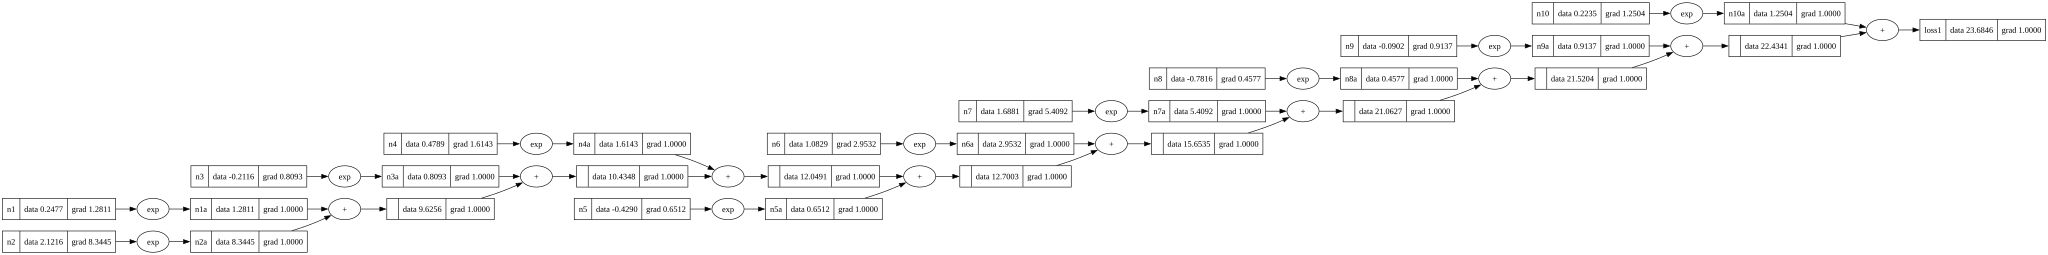

In [35]:
draw_dot(loss1)

In [36]:
n1, n1a

(Value(data=0.2477, grad=1.2810755518742938),
 Value(data=1.2810755518742938, grad=1))

In [51]:
m1 = Value(-0.5434, label = 'm1')
m2 = Value(-0.8391, label = 'm2')
m3 = Value(-1.9117, label = 'm3')
m4 = Value(-1.922, label = 'm4')
m5 = Value(-0.4209, label = 'm5')
m6 = Value(-0.2874, label = 'm6')
m7 = Value(0.7715, label = 'm7')
m8 = Value(0.7912, label = 'm8')
m9 = Value(0.2874, label = 'm9')
m10 = Value(-0.455, label = 'm10')

In [52]:
m1a = m1.exp(); m1a.label = 'm1a'
m2a = m2.exp(); m2a.label = 'm2a'
m3a = m3.exp(); m3a.label = 'm3a'
m4a = m4.exp(); m4a.label = 'm4a'
m5a = m5.exp(); m5a.label = 'm5a'
m6a = m6.exp(); m6a.label = 'm6a'
m7a = m7.exp(); m7a.label = 'm7a'
m8a = m8.exp(); m8a.label = 'm8a'
m9a = m9.exp(); m9a.label = 'm9a'
m10a = m10.exp(); m10a.label = 'm10a'

In [53]:
loss2 = m1a + m2a + m3a + m4a + m5a + m6a + m7a + m8a + m9a + m10a; loss2.label = 'loss2'

In [40]:
loss2

Value(data=9.05013542436278, grad=0)

In [42]:
loss2.backward()

v  Value(data=9.05013542436278, grad=0)
child  Value(data=8.415687456414553, grad=0)
v  Value(data=8.415687456414553, grad=0)
child  Value(data=7.0827301666453355, grad=0)
v  Value(data=7.0827301666453355, grad=0)
child  Value(data=2.206042089047639, grad=0)
v  Value(data=2.206042089047639, grad=0)
child  Value(data=0.7912, grad=0)
v  Value(data=0.7912, grad=0)
child  Value(data=4.876688077597696, grad=0)
v  Value(data=4.876688077597696, grad=0)
child  Value(data=2.713679743479744, grad=0)
v  Value(data=2.713679743479744, grad=0)
child  Value(data=0.7502115841784668, grad=0)
v  Value(data=0.7502115841784668, grad=0)
child  Value(data=-0.2874, grad=0)
v  Value(data=-0.2874, grad=0)
child  Value(data=1.963468159301277, grad=0)
v  Value(data=1.963468159301277, grad=0)
child  Value(data=0.656455743701372, grad=0)
v  Value(data=0.656455743701372, grad=0)
child  Value(data=-0.4209, grad=0)
v  Value(data=-0.4209, grad=0)
child  Value(data=1.307012415599905, grad=0)
v  Value(data=1.30701241559

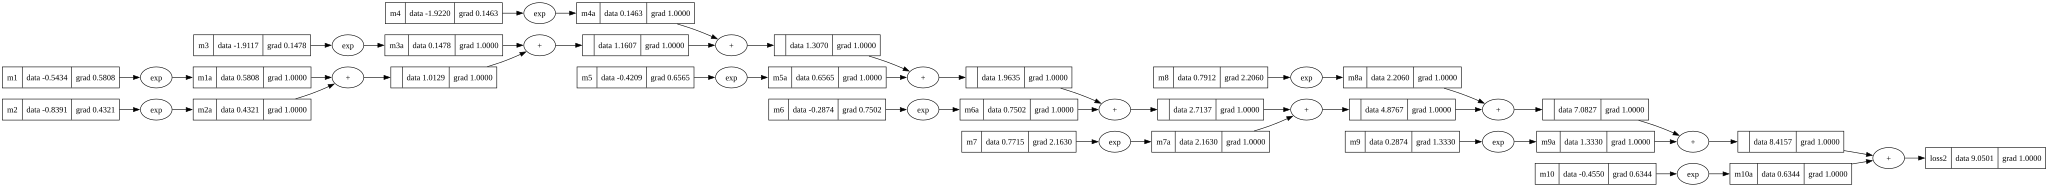

In [43]:
draw_dot(loss2)

In [54]:
loss = loss1 + loss2

In [55]:
print(loss)

Value(data=32.734727118123374, grad=0)


In [56]:
loss.backward()

v  Value(data=32.734727118123374, grad=0)
child  Value(data=23.68459169376059, grad=0)
v  Value(data=23.68459169376059, grad=0)
child  Value(data=1.2504456402764648, grad=0)
v  Value(data=1.2504456402764648, grad=0)
child  Value(data=0.2235, grad=0)
v  Value(data=0.2235, grad=0)
child  Value(data=22.434146053484127, grad=0)
v  Value(data=22.434146053484127, grad=0)
child  Value(data=0.9137484173115791, grad=0)
v  Value(data=0.9137484173115791, grad=0)
child  Value(data=-0.0902, grad=0)
v  Value(data=-0.0902, grad=0)
child  Value(data=21.52039763617255, grad=0)
v  Value(data=21.52039763617255, grad=0)
child  Value(data=21.062724488038533, grad=0)
v  Value(data=21.062724488038533, grad=0)
child  Value(data=15.653531020276834, grad=0)
v  Value(data=15.653531020276834, grad=0)
child  Value(data=12.700299504157393, grad=0)
v  Value(data=12.700299504157393, grad=0)
child  Value(data=12.04913957497636, grad=0)
v  Value(data=12.04913957497636, grad=0)
child  Value(data=1.614297697717094, grad=

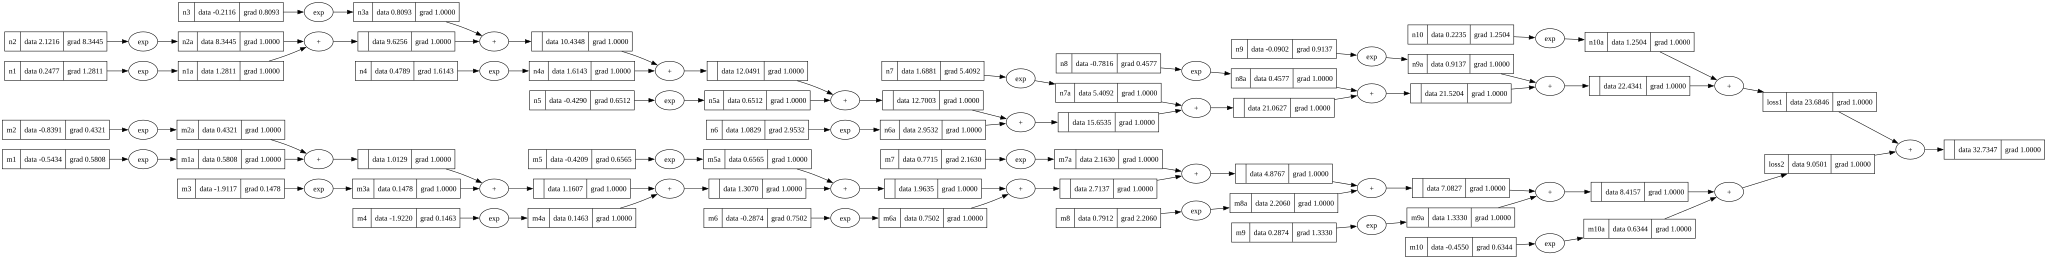

In [57]:
draw_dot(loss)

In [60]:
# END PART -> return x.exp() / (x.exp().sum(-1)).unsqueeze(-1)

In [61]:
# loss1 = n1a + n2a + n3a + n4a + n5a + n6a + n7a + n8a + n9a + n10a; loss1.label = 'loss1'

In [62]:
# loss2 = m1a + m2a + m3a + m4a + m5a + m6a + m7a + m8a + m9a + m10a; loss2.label = 'loss2'

In [63]:
n1a / loss1

Value(data=0.054088986140798746, grad=0)

In [64]:
# first branch
p1 = n1a / loss1
p2 = n2a / loss1
p3 = n3a / loss1
p4 = n4a / loss1
p5 = n5a / loss1
p6 = n6a / loss1
p7 = n7a / loss1
p8 = n8a / loss1
p9 = n9a / loss1
p10 = n10a / loss1

# second branch
p11 = m1a / loss2
p12 = m2a / loss2
p13 = m3a / loss2
p14 = m4a / loss2
p15 = m5a / loss2
p16 = m6a / loss2
p17 = m7a / loss2
p18 = m8a / loss2
p19 = m9a / loss2
p20 = m10a / loss2

In [65]:
p1

Value(data=0.054088986140798746, grad=0)

In [68]:
# pick index for labels [9 , 4] --> branch 1 (loss1) and branch 2 (loss2) --> p10, p15

In [69]:
p10, p15

(Value(data=0.05279574401976619, grad=0),
 Value(data=0.07253546084340425, grad=0))

In [70]:
p10.log(), p15.log()

(Value(data=-2.9413246972049807, grad=0),
 Value(data=-2.6236797216178616, grad=0))

In [71]:
last_loss = -(p10.log() + p15.log()) / 2
last_loss

Value(data=2.782502209411421, grad=0)

In [72]:
# putting together cross entropy in micrograd graph 

In [74]:
# initialize branch 1
n1 = Value(0.2477, label = 'n1')
n2 = Value(2.1216, label = 'n2')
n3 = Value(-0.2116, label = 'n3')
n4 = Value(0.4789, label = 'n4')
n5 = Value(-0.4290, label = 'n5')
n6 = Value(1.0829, label = 'n6')
n7 = Value(1.6881, label = 'n7')
n8 = Value(-0.7816, label = 'n8')
n9 = Value(-0.0902, label = 'n9')
n10 = Value(0.2235, label = 'n10')

# exp()
n1a = n1.exp(); n1a.label = 'n1a'
n2a = n2.exp(); n2a.label = 'n2a'
n3a = n3.exp(); n3a.label = 'n3a'
n4a = n4.exp(); n4a.label = 'n4a'
n5a = n5.exp(); n5a.label = 'n5a'
n6a = n6.exp(); n6a.label = 'n6a'
n7a = n7.exp(); n7a.label = 'n7a'
n8a = n8.exp(); n8a.label = 'n8a'
n9a = n9.exp(); n9a.label = 'n9a'
n10a = n10.exp(); n10a.label = 'n10a'

loss1 = n1a + n2a + n3a + n4a + n5a + n6a + n7a + n8a + n9a + n10a; loss1.label = 'loss1'

# initialize branch 2
m1 = Value(-0.5434, label = 'm1')
m2 = Value(-0.8391, label = 'm2')
m3 = Value(-1.9117, label = 'm3')
m4 = Value(-1.922, label = 'm4')
m5 = Value(-0.4209, label = 'm5')
m6 = Value(-0.2874, label = 'm6')
m7 = Value(0.7715, label = 'm7')
m8 = Value(0.7912, label = 'm8')
m9 = Value(0.2874, label = 'm9')
m10 = Value(-0.455, label = 'm10')

m1a = m1.exp(); m1a.label = 'm1a'
m2a = m2.exp(); m2a.label = 'm2a'
m3a = m3.exp(); m3a.label = 'm3a'
m4a = m4.exp(); m4a.label = 'm4a'
m5a = m5.exp(); m5a.label = 'm5a'
m6a = m6.exp(); m6a.label = 'm6a'
m7a = m7.exp(); m7a.label = 'm7a'
m8a = m8.exp(); m8a.label = 'm8a'
m9a = m9.exp(); m9a.label = 'm9a'
m10a = m10.exp(); m10a.label = 'm10a'

loss2 = m1a + m2a + m3a + m4a + m5a + m6a + m7a + m8a + m9a + m10a; loss2.label = 'loss2'

# first branch
p1 = n1a / loss1
p2 = n2a / loss1
p3 = n3a / loss1
p4 = n4a / loss1
p5 = n5a / loss1
p6 = n6a / loss1
p7 = n7a / loss1
p8 = n8a / loss1
p9 = n9a / loss1
p10 = n10a / loss1

# second branch
p11 = m1a / loss2
p12 = m2a / loss2
p13 = m3a / loss2
p14 = m4a / loss2
p15 = m5a / loss2
p16 = m6a / loss2
p17 = m7a / loss2
p18 = m8a / loss2
p19 = m9a / loss2
p20 = m10a / loss2

last_loss = -(p10.log() + p15.log()) / 2
last_loss

Value(data=2.782502209411421, grad=0)

In [75]:
last_loss.backward()

v  Value(data=2.782502209411421, grad=0)
child  Value(data=5.565004418822842, grad=0)
v  Value(data=5.565004418822842, grad=0)
child  Value(data=-1, grad=0)
v  Value(data=-1, grad=0)
child  Value(data=-5.565004418822842, grad=0)
v  Value(data=-5.565004418822842, grad=0)
child  Value(data=-2.6236797216178616, grad=0)
v  Value(data=-2.6236797216178616, grad=0)
child  Value(data=0.07253546084340425, grad=0)
v  Value(data=0.07253546084340425, grad=0)
child  Value(data=0.11049558411115268, grad=0)
v  Value(data=0.11049558411115268, grad=0)
child  Value(data=9.05013542436278, grad=0)
v  Value(data=9.05013542436278, grad=0)
child  Value(data=0.6344479679482282, grad=0)
v  Value(data=0.6344479679482282, grad=0)
child  Value(data=-0.455, grad=0)
v  Value(data=-0.455, grad=0)
child  Value(data=8.415687456414553, grad=0)
v  Value(data=8.415687456414553, grad=0)
child  Value(data=7.0827301666453355, grad=0)
v  Value(data=7.0827301666453355, grad=0)
child  Value(data=2.206042089047639, grad=0)
v  V

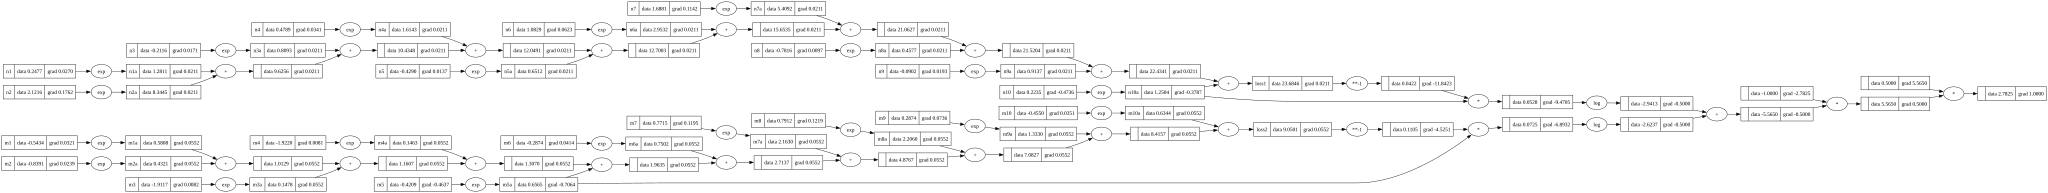

In [76]:
draw_dot(last_loss)

In [80]:
# others

In [83]:
import matplotlib.pyplot as plt

In [84]:
ns = torch.arange(0,5,0.01)

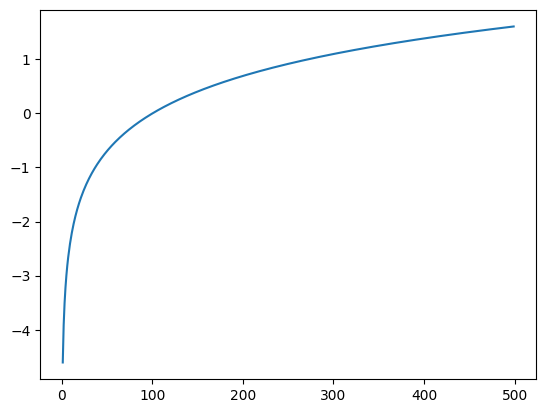

In [85]:
plt.plot(ns.log())

In [90]:
torch.tensor(0.0528).log()

tensor(-2.9412)

In [87]:
torch.sqrt(torch.tensor(2.0))

tensor(1.4142)

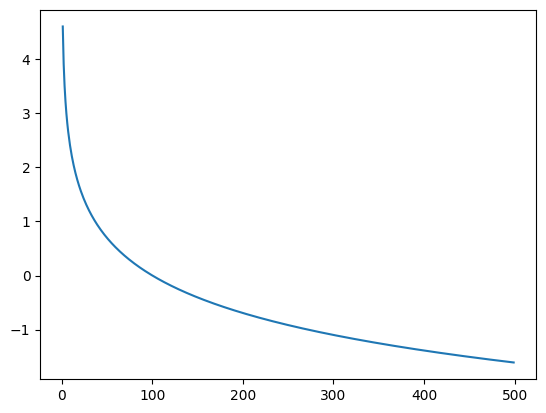

In [91]:
plt.plot(-ns.log())

In [93]:
-torch.tensor(0.0528).log(), -torch.tensor(0.0725).log()

(tensor(2.9412), tensor(2.6242))

In [97]:
xs[0].data

tensor([ 0.2477,  2.1216, -0.2116,  0.4789, -0.4290,  1.0829,  1.6881, -0.7816,
        -0.0902,  0.2235])

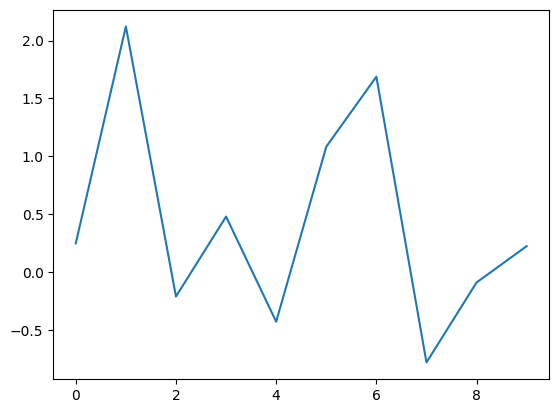

In [96]:
plt.plot(xs[0].data)

In [98]:
arr = []
INDEX = 1
for i in xs[0]:
    print(i.item())
    v = Value(i.item(), label='n'.join(str(INDEX)))
    arr.append(v)
    INDEX += 1
    print(v)

0.24770359694957733
Value(data=0.24770359694957733, grad=0)
2.121598243713379
Value(data=2.121598243713379, grad=0)
-0.21164020895957947
Value(data=-0.21164020895957947, grad=0)
0.4788804054260254
Value(data=0.4788804054260254, grad=0)
-0.4290335774421692
Value(data=-0.4290335774421692, grad=0)
1.0829006433486938
Value(data=1.0829006433486938, grad=0)
1.6880537271499634
Value(data=1.6880537271499634, grad=0)
-0.7815843820571899
Value(data=-0.7815843820571899, grad=0)
-0.0902344286441803
Value(data=-0.0902344286441803, grad=0)
0.22348833084106445
Value(data=0.22348833084106445, grad=0)


In [99]:
arr2 = []
for i in arr:
    print(i.exp())
    arr2.append(i.exp())

Value(data=1.2810801598467458, grad=0)
Value(data=8.34446332193148, grad=0)
Value(data=0.8092558081830562, grad=0)
Value(data=1.6142660665513395, grad=0)
Value(data=0.6511380652632368, grad=0)
Value(data=2.9532334160776905, grad=0)
Value(data=5.408943174754479, grad=0)
Value(data=0.4576802961028877, grad=0)
Value(data=0.9137169587339904, grad=0)
Value(data=1.250431048712684, grad=0)


In [100]:
arr3 = []
col = 0
for i in arr2:
    col += i
    arr3.append(col)
    print(col)

Value(data=1.2810801598467458, grad=0)
Value(data=9.625543481778227, grad=0)
Value(data=10.434799289961283, grad=0)
Value(data=12.049065356512623, grad=0)
Value(data=12.700203421775859, grad=0)
Value(data=15.65343683785355, grad=0)
Value(data=21.062380012608028, grad=0)
Value(data=21.520060308710914, grad=0)
Value(data=22.433777267444903, grad=0)
Value(data=23.684208316157587, grad=0)


In [101]:
col

Value(data=23.684208316157587, grad=0)

In [102]:
arr4 = []
idx = 0
for k in arr2:
    print(k / arr3[9])
    idx += 1
    arr4.append(k / arr3[9])

Value(data=0.054090056241093816, grad=0)
Value(data=0.35232181758166725, grad=0)
Value(data=0.0341685817562656, grad=0)
Value(data=0.06815790694806852, grad=0)
Value(data=0.027492498654431458, grad=0)
Value(data=0.124692089203715, grad=0)
Value(data=0.2283776220235509, grad=0)
Value(data=0.0193242809720878, grad=0)
Value(data=0.038579164080001956, grad=0)
Value(data=0.05279598253911777, grad=0)


In [103]:
__sum = 0
for i in arr4:
   __sum += i

In [104]:
__sum

Value(data=1.0, grad=0)